# Parte II. Clustering y detección de anomalías

**Integrantes:** Ricardo Acuña, Juan Aquino y Camilo Soto.

**Pregunta que responde.** ¿Qué tipos de proveedor existen en la contratación pública peruana, y cuáles combinan dependencia de un solo cliente con poca competencia? No se busca clasificar por tamaño, que ya sabemos que es muy desigual, sino por **comportamiento**: a cuántos clientes vende, con cuánta competencia gana, en cuántos mercados opera.

**Por qué le importa a quien supervisa.** El OECE y la Contraloría no pueden revisar 70 mil proveedores. Una tipología bien construida convierte esa masa en unos pocos perfiles con una política distinta para cada uno, y los outliers de densidad dan una cola de revisión corta y explicable.

**Dónde corre.** Spark para leer la base, estandarizar, reducir dimensión y para el KMeans de MLlib; local para el KMeans++ propio, el jerárquico y la densidad. La sección 4 mide los dos caminos y justifica la elección.

In [1]:
import sys, time
from pathlib import Path

# Los ayudantes del proyecto viven en notebooks/scripts. Se importan por
# nombre, no con asterisco, para que quede claro de donde sale cada uno.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "notebooks" / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import Window
from pyspark.sql import functions as F

from helpers import (PARQUET, BASE, FIGS, ARTEFACTOS, FIGURAS, HALLAZGOS, PALETA,
                     AZUL, ROJO, VERDE, MORADO, TEAL, TINTA, SUAVE, REJILLA, fmt, MILES,
                     abrir_spark, cronometro, medir, figura, exportar, hallazgo,
                     barras_h, barras_agrupadas, mapa_calor)
from algoritmos import kmeans, silueta, dbscan, aglomerativo

pd.set_option("display.width", 190)
pd.set_option("display.max_colwidth", 64)


spark = abrir_spark("P2-II-Clustering")
prov = spark.read.parquet(str(BASE / "caracteristicas_proveedores"))
print(f"{prov.count():,} proveedores con al menos una adjudicación")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/26 11:55:02 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


62,462 proveedores con al menos una adjudicación


## 1. Población, características y estandarización

**Población.** Solo proveedores con al menos tres adjudicaciones. No es por comodidad: las tasas que definen el comportamiento, como la cuota del mayor cliente o la tasa de postor único, valen exactamente 0 o 1 cuando se ganó una sola vez. Con esos proveedores dentro, el algoritmo encuentra esquinas del cubo y no perfiles. La Parte I mostró que la mayoría de proveedores tiene una o dos adjudicaciones; ellos son el ruido de fondo de un mercado atomizado, no un tipo de comportamiento.

**Características.** Doce, en cuatro grupos:

| Grupo | Variables | Transformación |
| --- | --- | --- |
| Escala | n_ganados, monto_total, monto_mediano | logaritmo, porque se reparten en varios órdenes de magnitud |
| Alcance | n_entidades, n_departamentos, n_familias | logaritmo |
| Dependencia y continuidad | cuota_cliente_top, meses_activos | ninguna, ya están acotadas |
| Competencia y rubro | tasa_victoria, pct_postor_unico, pct_sin_concurso, pct_obras | ninguna |

Se dejan fuera n_participaciones, que es casi n_ganados dividido entre la tasa de victoria, y pct_servicios, que es casi el complemento de bienes más obras. Variables redundantes pesan dos veces en una distancia euclidiana.

**Estandarización.** Media cero y desviación uno. Sin ella, monto_total en logaritmo, que va de 7 a 20, dominaría a una tasa que va de 0 a 1, y el clustering sería solo sobre tamaño.

In [2]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA

LOGS = ["n_ganados", "monto_total", "monto_mediano", "n_entidades", "n_departamentos", "n_familias"]
TASAS = ["cuota_cliente_top", "meses_activos", "tasa_victoria", "pct_postor_unico",
         "pct_sin_concurso", "pct_obras"]
VARIABLES = LOGS + TASAS

pob = prov.filter("n_ganados >= 3").fillna(0, subset=TASAS)
for c in LOGS:
    pob = pob.withColumn(c + "_l", F.log1p(c))
entrada = [c + "_l" for c in LOGS] + TASAS
prep = Pipeline(stages=[
    VectorAssembler(inputCols=entrada, outputCol="crudo"),
    StandardScaler(inputCol="crudo", outputCol="z", withMean=True, withStd=True),
    PCA(k=len(entrada), inputCol="z", outputCol="pca"),
]).fit(pob)
pob = prep.transform(pob).cache()
n = pob.count()
print(f"{n:,} proveedores recurrentes, el {100*n/prov.count():.0f} % de los que ganaron algo")

12,062 proveedores recurrentes, el 19 % de los que ganaron algo


**Reducción de dimensión con PCA.** Las variables de escala están correlacionadas entre sí: quien gana muchas veces suele vender más y estar activo más meses. PCA rota el espacio a ejes no correlacionados y ordena la varianza. Se conservan las componentes que explican el 90 por ciento, por dos razones: el tamaño deja de contar tres veces en la distancia, y DBSCAN, que depende de una distancia con sentido, funciona mejor en pocas dimensiones.


Lectura de f09_pca_varianza
El comportamiento de un proveedor no se reduce a su tamaño: la primera componente explica solo el 40 por ciento de la varianza y hacen falta 6 de doce para llegar al 90 por ciento. La primera la forman sobre todo n_entidades, n_ganados, meses_activos, es decir escala y alcance; la segunda, pct_postor_unico, pct_sin_concurso, monto_mediano. Que la varianza esté repartida confirma que hay más de un eje de comportamiento, y justifica no resumir a los proveedores en un ranking de monto. Se trabaja con 6 componentes.



,PC1,PC2,PC3
n_ganados,0.37,0.28,0.03
monto_total,0.33,-0.09,0.46
monto_mediano,0.16,-0.32,0.54
n_entidades,0.42,0.14,-0.05
n_departamentos,0.33,0.18,-0.14
n_familias,0.25,0.12,0.07
cuota_cliente_top,-0.33,-0.00,0.17
meses_activos,0.36,0.30,0.05
tasa_victoria,-0.23,0.32,0.26
pct_postor_unico,-0.21,0.50,0.25


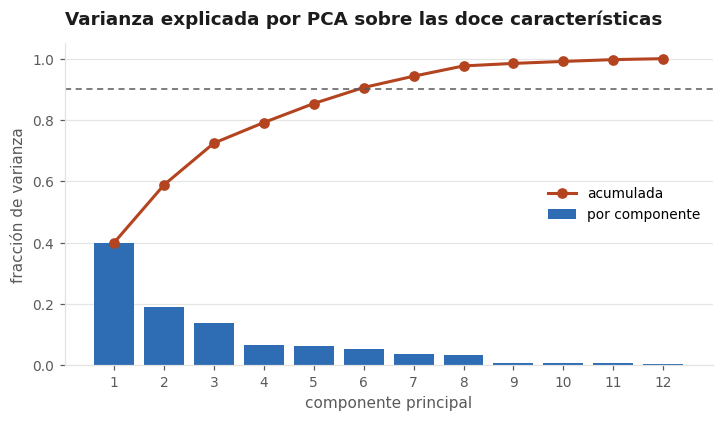

In [3]:
pca = prep.stages[-1]
varianza = np.array(pca.explainedVariance)
acum = np.cumsum(varianza)
K_PCA = int(np.searchsorted(acum, 0.90) + 1)
# El signo de una componente es arbitrario. Se orienta cada una para que su
# carga mas grande sea positiva: asi PC1 crece con la escala y se lee de
# izquierda a derecha. Cambiar signos no altera ninguna distancia.
P = pca.pc.toArray()
SIGNOS = np.sign(P[np.abs(P).argmax(0), np.arange(P.shape[1])])
cargas = pd.DataFrame((P * SIGNOS)[:, :3], index=VARIABLES, columns=["PC1", "PC2", "PC3"]).round(2)

fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.bar(range(1, len(varianza) + 1), varianza, color=AZUL, label="por componente")
ax.plot(range(1, len(varianza) + 1), acum, "o-", color=ROJO, lw=2, label="acumulada")
ax.axhline(.9, color=SUAVE, ls=(0, (4, 3)), lw=1)
ax.set_xticks(range(1, len(varianza) + 1)); ax.set_xlabel("componente principal")
ax.set_ylabel("fracción de varianza"); ax.legend(loc="center right")
ax.set_title("Varianza explicada por PCA sobre las doce características", loc="left", pad=12)
ax.grid(axis="y", alpha=.9); ax.set_axisbelow(True)
pc1 = cargas.PC1.abs().sort_values(ascending=False).index[:3].tolist()
pc2 = cargas.PC2.abs().sort_values(ascending=False).index[:3].tolist()
figura(fig, "f09_pca_varianza", f"""
El comportamiento de un proveedor no se reduce a su tamaño: la primera componente explica solo el
{100*varianza[0]:.0f} por ciento de la varianza y hacen falta {K_PCA} de doce para llegar al 90 por
ciento. La primera la forman sobre todo {', '.join(pc1)}, es decir escala y alcance; la segunda,
{', '.join(pc2)}. Que la varianza esté repartida confirma que hay más de un eje de comportamiento, y
justifica no resumir a los proveedores en un ranking de monto. Se trabaja con {K_PCA} componentes.""")
cargas

In [4]:
from pyspark.ml.functions import vector_to_array
datos = (pob.withColumn("pca_k", F.slice(vector_to_array("pca"), 1, K_PCA))
            .withColumn("z_arr", vector_to_array("z")))
local = datos.select("nodo", "clave", "nombre", "tipo", *VARIABLES, "pca_k", "z_arr").toPandas()
X = np.vstack(local.pca_k.values) * SIGNOS[:K_PCA]
Z = np.vstack(local.z_arr.values)
print(X.shape, "matriz local para los métodos propios")

(12062, 6) matriz local para los métodos propios


## 2. KMeans++ y la elección de k

Se corre el KMeans propio, con la inicialización k-means++ de la lecture, para k de 2 a 12, y para cada k se registran el SSE y la silueta. Los dos criterios se leen juntos porque dicen cosas distintas: el SSE siempre baja al subir k y se busca el codo donde deja de bajar rápido; la silueta mide si cada punto está más cerca de su cluster que del siguiente, y no crece por sí sola.

En paralelo se corre KMeans de Spark MLlib, que inicializa con k-means paralelo, la variante distribuida de k-means++, para contrastar.

In [5]:
from pyspark.ml.clustering import KMeans as KMeansSpark
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.linalg import Vectors, VectorUDT

sdf = spark.createDataFrame([(Vectors.dense(x),) for x in X], ["f"]).cache()
evaluador = ClusteringEvaluator(featuresCol="f", predictionCol="prediction")
filas = []
for k in range(2, 13):
    etq, C, sse, it = kmeans(X, k, semilla=7)
    m = KMeansSpark(k=k, seed=7, featuresCol="f").fit(sdf)
    filas.append({"k": k, "sse_propio": sse, "sse_mllib": m.summary.trainingCost,
                  "silueta_propia": silueta(X, etq, 3000), "silueta_mllib": evaluador.evaluate(m.transform(sdf)),
                  "iteraciones": it})
eleccion = pd.DataFrame(filas)
# Codo: el k mas lejano de la cuerda que une el primer y el ultimo SSE normalizados.
x = (eleccion.k - eleccion.k.min()) / (eleccion.k.max() - eleccion.k.min())
y = (eleccion.sse_propio - eleccion.sse_propio.min()) / (eleccion.sse_propio.max() - eleccion.sse_propio.min())
eleccion["dist_cuerda"] = (1 - x) - y
exportar(eleccion.round(4), "p2_eleccion_k", "SSE y silueta por k, propio y MLlib")
eleccion.round(3)

,k,sse_propio,sse_mllib,silueta_propia,silueta_mllib,iteraciones,dist_cuerda
0,2,97086.774,101448.841,0.308,0.564,18,0.000
1,3,82814.275,71453.119,0.310,0.554,24,0.118
2,4,58426.796,58426.560,0.387,0.570,24,0.389
3,5,49883.121,53949.784,0.267,0.558,44,0.419
4,6,44658.714,44659.204,0.249,0.372,40,0.399
5,7,40703.681,40709.046,0.260,0.390,37,0.359
6,8,39597.149,37752.745,0.251,0.382,48,0.276
7,9,35434.670,36600.753,0.234,0.361,66,0.240
8,10,33901.991,34291.737,0.233,0.354,55,0.163
9,11,32952.361,32597.293,0.226,0.336,63,0.077



Lectura de f10_eleccion_k
El codo del SSE está en k = 5 y la silueta más alta en k = 4, con 0.387. Se adopta k = 4: el de la silueta, porque en el codo la silueta cae a 0.267, más de 0,05 por debajo. La silueta de MLlib da valores más altos porque usa la distancia euclidiana al cuadrado, pero su máximo también está en k = 4. Una silueta de ese orden dice que los grupos existen pero no son islas: el comportamiento de los proveedores es un continuo con regiones más densas, que es lo esperable en un mercado y es la razón para complementar con un método de densidad. El SSE propio y el de MLlib coinciden en k = 4; en 5 de los 11 valores de k el de MLlib queda más de un 1 por ciento por encima, porque su inicialización cayó en un mínimo local peor, que es justo el riesgo que k-means++ reduce.



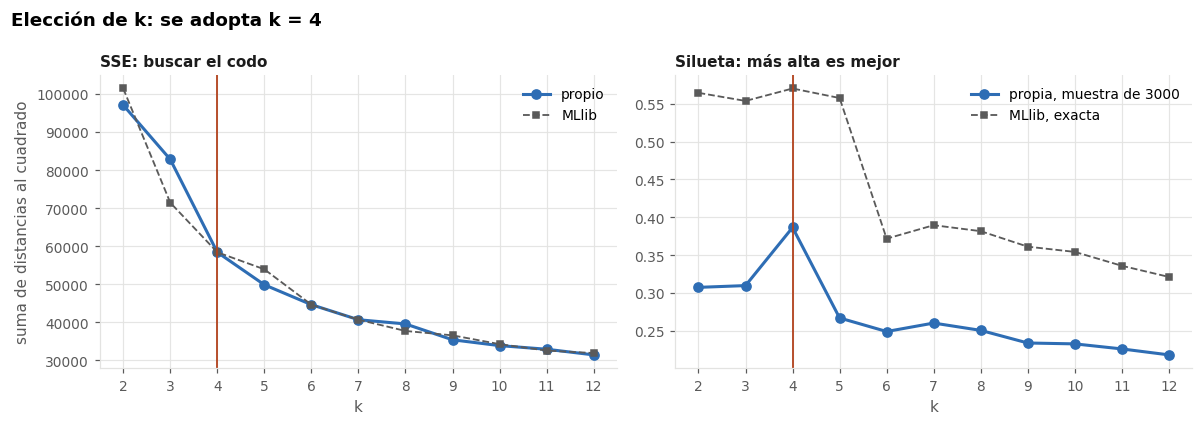

In [6]:
K_CODO = int(eleccion.loc[eleccion.dist_cuerda.idxmax(), "k"])
K_SIL = int(eleccion.loc[eleccion.silueta_propia.idxmax(), "k"])
# Entre el codo y la silueta se elige el k del codo salvo que su silueta
# caiga mas de 0,05 bajo la mejor: el codo da perfiles mas finos.
mejor_sil = eleccion.silueta_propia.max()
K = K_CODO if eleccion.set_index("k").loc[K_CODO, "silueta_propia"] >= mejor_sil - .05 else K_SIL

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
axes[0].plot(eleccion.k, eleccion.sse_propio, "o-", color=AZUL, lw=2, label="propio")
axes[0].plot(eleccion.k, eleccion.sse_mllib, "s--", color=SUAVE, lw=1.2, ms=4, label="MLlib")
axes[0].axvline(K, color=ROJO, lw=1.2); axes[0].set_title("SSE: buscar el codo", loc="left", fontsize=10)
axes[0].set_xlabel("k"); axes[0].set_ylabel("suma de distancias al cuadrado"); axes[0].legend()
axes[1].plot(eleccion.k, eleccion.silueta_propia, "o-", color=AZUL, lw=2, label="propia, muestra de 3000")
axes[1].plot(eleccion.k, eleccion.silueta_mllib, "s--", color=SUAVE, lw=1.2, ms=4, label="MLlib, exacta")
axes[1].axvline(K, color=ROJO, lw=1.2); axes[1].set_title("Silueta: más alta es mejor", loc="left", fontsize=10)
axes[1].set_xlabel("k"); axes[1].legend()
for ax in axes: ax.grid(alpha=.9); ax.set_axisbelow(True); ax.set_xticks(eleccion.k)
fig.suptitle(f"Elección de k: se adopta k = {K}", x=.01, ha="left", fontweight="bold"); fig.tight_layout()
fila = eleccion.set_index("k").loc[K]
if K_CODO == K_SIL:
    razon = "los dos criterios coinciden"
elif K == K_CODO:
    razon = "el codo, porque su silueta queda a menos de 0,05 de la mejor y da perfiles más finos"
else:
    razon = (f"el de la silueta, porque en el codo la silueta cae a "
             f"{eleccion.set_index('k').loc[K_CODO, 'silueta_propia']:.3f}, más de 0,05 por debajo")
K_SIL_MLLIB = int(eleccion.loc[eleccion.silueta_mllib.idxmax(), "k"])
n_peor = int((eleccion.sse_mllib > 1.01 * eleccion.sse_propio).sum())
figura(fig, "f10_eleccion_k", f"""
El codo del SSE está en k = {K_CODO} y la silueta más alta en k = {K_SIL}, con {mejor_sil:.3f}. Se
adopta k = {K}: {razon}. La silueta de MLlib da valores más altos porque usa la distancia
euclidiana al cuadrado, pero su máximo también está en k = {K_SIL_MLLIB}. Una silueta de ese orden
dice que los grupos existen pero no son islas: el comportamiento de los proveedores es un continuo
con regiones más densas, que es lo esperable en un mercado y es la razón para complementar con un
método de densidad. El SSE propio y el de MLlib coinciden en k = {K}; en {n_peor} de los
{len(eleccion)} valores de k el de MLlib queda más de un 1 por ciento por encima, porque su
inicialización cayó en un mínimo local peor, que es justo el riesgo que k-means++ reduce.""")

## 3. Qué perfil representa cada cluster

El centroide en el espacio de PCA no se puede leer. Se lee el promedio de cada cluster en las variables estandarizadas: un valor de 1 significa una desviación estándar por encima del proveedor recurrente típico.

In [7]:
etq, C, sse, _ = kmeans(X, K, semilla=7)
local["cluster"] = etq
perfil_z = pd.DataFrame(Z, columns=VARIABLES).groupby(etq).mean()
perfil = local.groupby("cluster").agg(
    proveedores=("nodo", "size"), monto_total=("monto_total", "sum"),
    n_ganados=("n_ganados", "median"), n_entidades=("n_entidades", "median"),
    cuota_cliente_top=("cuota_cliente_top", "median"), tasa_victoria=("tasa_victoria", "median"),
    pct_postor_unico=("pct_postor_unico", "mean"), pct_sin_concurso=("pct_sin_concurso", "mean"),
    pct_obras=("pct_obras", "mean"), n_departamentos=("n_departamentos", "median"))
perfil["pct_proveedores"] = (100 * perfil.proveedores / perfil.proveedores.sum()).round(1)
perfil["pct_monto"] = (100 * perfil.monto_total / perfil.monto_total.sum()).round(1)

# Nombre de cada cluster a partir de sus dos rasgos mas marcados.
RASGO = {"n_ganados": ("muchas adjudicaciones", "pocas adjudicaciones"),
         "monto_total": ("gran volumen", "poco volumen"),
         "monto_mediano": ("contratos grandes", "contratos pequeños"),
         "n_entidades": ("muchos clientes", "pocos clientes"),
         "n_departamentos": ("alcance nacional", "alcance local"),
         "n_familias": ("muy diversificado", "especializado"),
         "cuota_cliente_top": ("dependiente de un cliente", "clientes repartidos"),
         "meses_activos": ("actividad continua", "actividad esporádica"),
         "tasa_victoria": ("gana casi siempre", "gana poco"),
         "pct_postor_unico": ("gana sin rivales", "gana compitiendo"),
         "pct_sin_concurso": ("contratado sin concurso", "contratado por concurso"),
         "pct_obras": ("obras", "bienes y servicios")}
def nombrar(fila):
    top = fila.abs().sort_values(ascending=False).index[:2]
    return ", ".join(RASGO[v][0 if fila[v] > 0 else 1] for v in top)
perfil["rasgos"] = perfil_z.apply(nombrar, axis=1)
# Nombre de negocio: se asigna por el rasgo dominante de cada cluster, en este
# orden, y el que no destaca en nada es el proveedor competitivo tipico.
cautivo = (perfil_z.cuota_cliente_top + perfil_z.pct_postor_unico + perfil_z.pct_sin_concurso).idxmax()
nombres_c = {cautivo: "cautivo sin competencia"}
for col, nombre in [("pct_obras", "contratista de obra"), ("n_ganados", "gran proveedor recurrente")]:
    resto = perfil_z.drop(index=list(nombres_c))
    if len(resto) and resto[col].max() > .5:
        nombres_c[resto[col].idxmax()] = nombre
perfil["perfil"] = [nombres_c.get(c, "competitivo típico") for c in perfil.index]
exportar(perfil.reset_index().round(3), "p2_perfiles", "Perfil de cada cluster de proveedores")
exportar(perfil_z.reset_index().round(3), "p2_perfiles_z", "Promedio estandarizado de cada variable por cluster")
perfil[["perfil", "rasgos", "proveedores", "pct_proveedores", "pct_monto", "n_ganados", "n_entidades",
        "cuota_cliente_top", "tasa_victoria", "pct_postor_unico", "pct_sin_concurso"]].round(2)

,perfil,rasgos,proveedores,pct_proveedores,pct_monto,n_ganados,n_entidades,cuota_cliente_top,tasa_victoria,pct_postor_unico,pct_sin_concurso
cluster,,,,,,,,,,,
0,competitivo típico,"contratado por concurso, actividad esporádica",7628,63.2,18.3,4.0,3.0,0.67,0.21,0.04,0.05
1,cautivo sin competencia,"gana sin rivales, contratado sin concurso",1260,10.4,2.9,3.0,1.0,1.00,1.00,0.91,0.96
2,contratista de obra,"obras, contratos grandes",1054,8.7,29.9,4.0,3.0,0.64,0.25,0.06,0.10
3,gran proveedor recurrente,"muchas adjudicaciones, actividad continua",2120,17.6,48.9,15.0,9.0,0.35,0.16,0.07,0.08



Lectura de f11_perfiles_cluster
El cluster 1, el cautivo sin competencia, es la respuesta directa a la pregunta 1: reúne 1,260 proveedores, el 10 por ciento de los recurrentes, que en mediana obtienen el 100 por ciento de su monto de un solo cliente, y el 91 por ciento de lo que ganan lo ganan sin otro postor. Mueven el 2.9 por ciento del monto, S/ 1,581 millones. En el otro extremo, el cluster 3, el gran proveedor recurrente, concentra el 49 por ciento del monto con el 18 por ciento de los proveedores. Cada fila es un perfil de comportamiento distinto y por eso pide una política de supervisión distinta, no un mismo umbral de monto para todos.



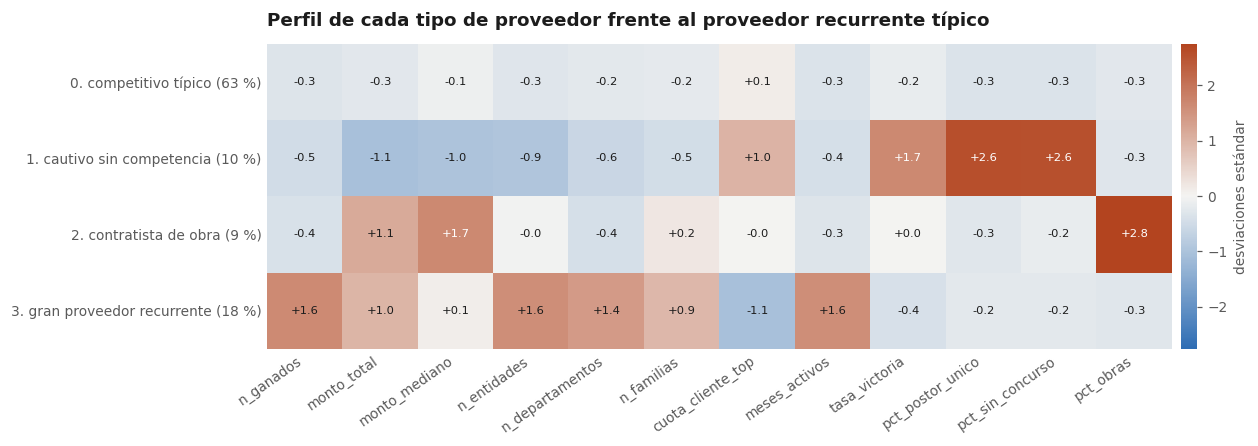

In [8]:
from matplotlib.colors import LinearSegmentedColormap
divergente = LinearSegmentedColormap.from_list("div", [AZUL, "#F4F4F2", ROJO])
fig, ax = plt.subplots(figsize=(11, 1.4 + .55 * K))
lim = np.abs(perfil_z.values).max()
im = ax.imshow(perfil_z.values, cmap=divergente, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=35, ha="right")
ax.set_yticks(range(K), [f"{c}. {perfil.perfil[c]} ({perfil.pct_proveedores[c]:.0f} %)" for c in perfil.index])
for i in range(K):
    for j in range(len(VARIABLES)):
        v = perfil_z.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > .6 * lim else TINTA)
cb = fig.colorbar(im, ax=ax, fraction=.025, pad=.01); cb.outline.set_visible(False)
cb.set_label("desviaciones estándar", color=SUAVE, fontsize=9)
ax.set_title("Perfil de cada tipo de proveedor frente al proveedor recurrente típico", loc="left", pad=12)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)

riesgo = cautivo
pr = perfil.loc[riesgo]
grande = perfil.pct_monto.idxmax()
figura(fig, "f11_perfiles_cluster", f"""
El cluster {riesgo}, el {pr.perfil}, es la respuesta directa a la pregunta 1: reúne
{pr.proveedores:,} proveedores, el {pr.pct_proveedores:.0f} por ciento de los recurrentes, que en
mediana obtienen el {100*pr.cuota_cliente_top:.0f} por ciento de su monto de un solo cliente, y el
{100*pr.pct_postor_unico:.0f} por ciento de lo que ganan lo ganan sin otro postor. Mueven el
{pr.pct_monto:.1f} por ciento del monto, S/ {pr.monto_total/1e6:,.0f} millones. En el otro extremo, el cluster
{grande}, el {perfil.perfil[grande]}, concentra el {perfil.pct_monto[grande]:.0f} por ciento del monto con el
{perfil.pct_proveedores[grande]:.0f} por ciento de los proveedores. Cada fila es un perfil de
comportamiento distinto y por eso pide una política de supervisión distinta, no un mismo umbral de
monto para todos.""")

In [9]:
hallazgo("II", "Existe un perfil de proveedor cautivo y se puede aislar",
         f"""{pr.proveedores:,} proveedores recurrentes forman un grupo propio: dependen de una sola
         entidad para el {100*pr.cuota_cliente_top:.0f} por ciento de su monto en mediana y ganan sin otro
         postor el {100*pr.pct_postor_unico:.0f} por ciento de las veces. Juntos suman el
         {pr.pct_monto:.1f} por ciento del monto adjudicado a recurrentes, S/ {pr.monto_total/1e6:,.0f} millones.
         Casi todo lo que ganan lo ganan sin concurso, por contratación directa o régimen especial. No es una irregularidad en sí,
         pero es la combinación que vuelve vulnerable a una entidad frente a su proveedor.""",
         f"""Usar el cluster {riesgo} como lista de vigilancia: para cada par entidad y proveedor del
         grupo, revisar si la falta de competencia se explica por el rubro o la geografía, y exigir
         estudio de mercado ampliado en sus próximas convocatorias.""",
         "f11_perfiles_cluster, p2_perfiles")


HALLAZGO. Existe un perfil de proveedor cautivo y se puede aislar
1,260 proveedores recurrentes forman un grupo propio: dependen de una sola entidad para el 100 por ciento de su monto en mediana y ganan sin otro postor el 91 por ciento de las veces. Juntos suman el 2.9 por ciento del monto adjudicado a recurrentes, S/ 1,581 millones. Casi todo lo que ganan lo ganan sin concurso, por contratación directa o régimen especial. No es una irregularidad en sí, pero es la combinación que vuelve vulnerable a una entidad frente a su proveedor.
Accion propuesta: Usar el cluster 1 como lista de vigilancia: para cada par entidad y proveedor del grupo, revisar si la falta de competencia se explica por el rubro o la geografía, y exigir estudio de mercado ampliado en sus próximas convocatorias.



## 4. KMeans de MLlib frente al propio, y si Spark conviene aquí

Se compara en el k adoptado la calidad, el acuerdo entre las dos particiones y el tiempo.

In [10]:
from sklearn.metrics import adjusted_rand_score
modelo_spark = KMeansSpark(k=K, seed=7, featuresCol="f").fit(sdf)
etq_spark = np.array([r.prediction for r in modelo_spark.transform(sdf).select("prediction").collect()])
t_propio = medir(lambda: kmeans(X, K, semilla=7))
t_spark = medir(lambda: KMeansSpark(k=K, seed=7, featuresCol="f").fit(sdf))
ari = adjusted_rand_score(etq, etq_spark)
spark_vs = pd.DataFrame([
    {"implementacion": "KMeans++ propio, numpy", "sse": sse, "segundos": t_propio},
    {"implementacion": "KMeans MLlib, k-means paralelo", "sse": modelo_spark.summary.trainingCost, "segundos": t_spark}])
exportar(spark_vs.round(4), "p2_spark_vs_local", "KMeans propio frente a MLlib en el k adoptado")
print(f"acuerdo entre particiones, ARI = {ari:.3f}")
spark_vs.round(3)

acuerdo entre particiones, ARI = 0.997


,implementacion,sse,segundos
0,"KMeans++ propio, numpy",58426.796,0.085
1,"KMeans MLlib, k-means paralelo",58426.560,2.300


Con unas decenas de miles de puntos en pocas dimensiones, la matriz cabe en memoria y una iteración de Lloyd es un producto de matrices: numpy lo resuelve en milisegundos, mientras Spark paga la planificación de cada iteración como un trabajo distribuido. **Spark no conviene para el clustering a esta escala**, y se usa aquí para lo que sí aporta: leer y transformar la base con el mismo código que correría en un clúster, y como contraste de la implementación propia. Si la población fueran millones de proveedores o el vector tuviera cientos de dimensiones, el orden se invertiría y KMeans de MLlib sería la herramienta, sin cambiar nada más del notebook.

Un ARI alto indica que las dos implementaciones encuentran la misma estructura aunque partan de inicializaciones distintas, lo que es evidencia de que los clusters no son un accidente de la semilla.

**Estabilidad de la partición.** Una silueta del orden de 0,4 dice que los grupos existen pero no son islas, y la pregunta natural es si otra semilla u otra muestra darían otros grupos. Se repite KMeans++ con diez semillas sobre todos los proveedores y con diez submuestras del 80 por ciento, y cada resultado se compara con la partición adoptada con el índice de Rand ajustado (ARI): 1 es la misma partición y 0 es lo que daría el azar.

In [11]:
rng_e = np.random.default_rng(0)
ari_semillas = [adjusted_rand_score(etq, kmeans(X, K, semilla=s)[0]) for s in range(10)]
ari_sub = []
for _ in range(10):
    idx = rng_e.choice(len(X), int(.8 * len(X)), replace=False)
    ari_sub.append(adjusted_rand_score(etq[idx], kmeans(X[idx], K, semilla=7)[0]))
estabilidad = pd.DataFrame({"prueba": ["semillas 0 a 9", "submuestras del 80 %"],
                            "ari_medio": [np.mean(ari_semillas), np.mean(ari_sub)],
                            "ari_minimo": [min(ari_semillas), min(ari_sub)],
                            "corridas_con_ari_de_0_9_o_mas": [sum(a >= .9 for a in ari_semillas),
                                                              sum(a >= .9 for a in ari_sub)]})
exportar(estabilidad.round(3), "p2_estabilidad", "ARI de KMeans frente a la particion adoptada, por semilla y por submuestra")
print(f"Con otra semilla la partición se repite casi exacta, ARI medio {np.mean(ari_semillas):.3f}. Con "
      f"submuestras del 80 por ciento, {sum(a >= .9 for a in ari_sub)} de 10 recuperan los mismos grupos y el "
      f"ARI medio es {np.mean(ari_sub):.3f}."
      + (" La tipología no es un accidente de la semilla." if np.mean(ari_semillas) >= .9 else ""))
estabilidad.round(3)

Con otra semilla la partición se repite casi exacta, ARI medio 0.998. Con submuestras del 80 por ciento, 9 de 10 recuperan los mismos grupos y el ARI medio es 0.925. La tipología no es un accidente de la semilla.


,prueba,ari_medio,ari_minimo,corridas_con_ari_de_0_9_o_mas
0,semillas 0 a 9,0.998,0.997,10
1,submuestras del 80 %,0.925,0.366,9


## 5. Jerárquico aglomerativo sobre una muestra

El jerárquico necesita la matriz completa de distancias, de orden n al cuadrado en memoria y n al cubo en tiempo en su versión directa: con decenas de miles de puntos no es viable, así que se aplica sobre una muestra de 2.000 proveedores. Se usa el enlace de Ward, que fusiona en cada paso el par cuya unión menos aumenta la varianza interna y es el análogo jerárquico de KMeans; el enlace por centroide de la lecture se verifica primero con la implementación propia contra scipy sobre 200 puntos.

alturas de fusión iguales a scipy: True



Lectura de f12_dendrograma
El dendrograma confirma la estructura por un camino independiente: cortado en 4 grupos, el jerárquico de Ward coincide con KMeans con un ARI de 0.62 sobre la misma muestra. Las fusiones más altas, a la derecha del eje, unen grupos muy distintos y son las que la línea roja corta; por debajo de ella las fusiones son cada vez más bajas y parejas, sin un salto que pida un corte más fino. Esa forma, unas pocas ramas grandes y muchas pequeñas, describe un mercado con pocos perfiles de comportamiento bien separados y mucha variación individual dentro de cada uno.



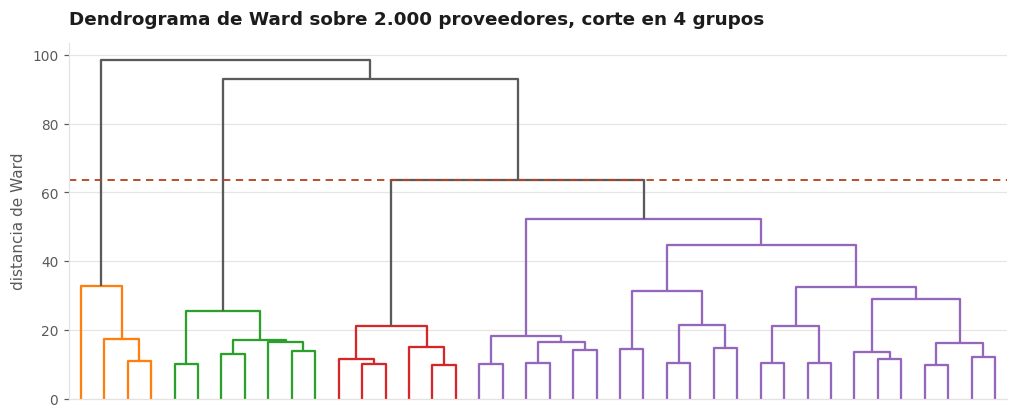

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
rng = np.random.default_rng(7)
m200 = rng.choice(len(X), 200, replace=False)
propio = aglomerativo(X[m200])
referencia = linkage(X[m200], "centroid")
print("alturas de fusión iguales a scipy:", np.allclose(np.sort(propio[:, 2]), np.sort(referencia[:, 2])))

muestra = rng.choice(len(X), 2000, replace=False)
enlace = linkage(X[muestra], "ward")
corte = fcluster(enlace, K, criterion="maxclust")
ari_jer = adjusted_rand_score(etq[muestra], corte)

fig, ax = plt.subplots(figsize=(11, 4.2))
dendrogram(enlace, truncate_mode="lastp", p=40, ax=ax, color_threshold=enlace[-(K - 1), 2],
           above_threshold_color=SUAVE, no_labels=True)
ax.axhline(enlace[-(K - 1), 2], color=ROJO, ls=(0, (4, 3)), lw=1.2)
ax.set_ylabel("distancia de Ward"); ax.set_title(f"Dendrograma de Ward sobre 2.000 proveedores, corte en {K} grupos", loc="left", pad=12)
ax.grid(axis="y", alpha=.9); ax.set_axisbelow(True)
saltos = np.diff(enlace[-12:, 2])[::-1]
figura(fig, "f12_dendrograma", f"""
El dendrograma confirma la estructura por un camino independiente: cortado en {K} grupos, el
jerárquico de Ward coincide con KMeans con un ARI de {ari_jer:.2f} sobre la misma muestra. Las
fusiones más altas, a la derecha del eje, unen grupos muy distintos y son las que la línea roja
corta; por debajo de ella las fusiones son cada vez más bajas y parejas, sin un salto que pida un
corte más fino. Esa forma, unas pocas ramas grandes y muchas pequeñas, describe un mercado con
pocos perfiles de comportamiento bien separados y mucha variación individual dentro de cada uno.""")

## 6. Densidad: DBSCAN propio, DBSCAN de scikit-learn y HDBSCAN

KMeans asigna todo punto a algún cluster, incluso al proveedor más extraño. Los métodos de densidad no: un punto que no tiene suficientes vecinos cerca queda como **ruido**, y eso es exactamente lo que se quiere para detectar anomalías.

**Elección de los parámetros.** min_pts se fija en el doble de la dimensión, la regla habitual, y eps con el gráfico de distancia al k-ésimo vecino: ordenadas de menor a mayor, la curva es plana mientras se está dentro de regiones densas y se dispara al llegar a los puntos aislados. El eps es la altura de ese codo.


Lectura de f13_k_distancia
La curva es plana para la gran mayoría de proveedores y se dispara al final: el codo está en una distancia de 1.31, que se adopta como eps con min_pts = 12. El 7.0 por ciento de los proveedores tiene a su vecino número 12 más lejos que eso. Ese tramo empinado es la cola de comportamientos que no se parecen a ningún otro, y es la candidata natural a anomalía: no hay que fijar a mano qué es raro, la propia densidad del dato lo dice.



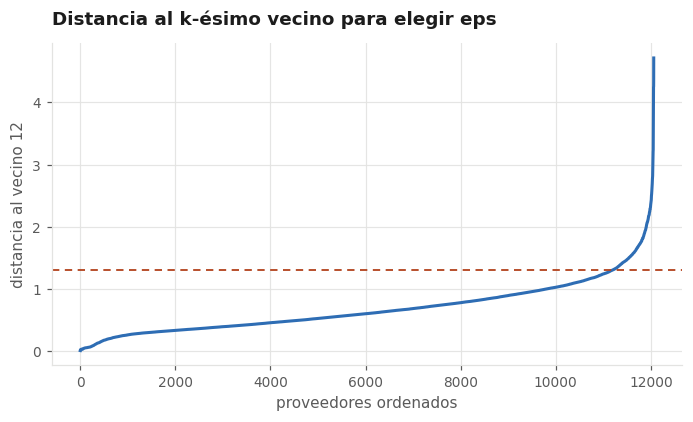

In [13]:
from scipy.spatial import cKDTree
MIN_PTS = 2 * K_PCA
dist_k = np.sort(cKDTree(X).query(X, MIN_PTS)[0][:, -1])
xs = np.linspace(0, 1, len(dist_k)); ys = (dist_k - dist_k.min()) / (dist_k.max() - dist_k.min())
EPS = float(dist_k[np.argmax(xs - ys)])

fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.plot(np.arange(len(dist_k)), dist_k, color=AZUL, lw=2)
ax.axhline(EPS, color=ROJO, ls=(0, (4, 3)), lw=1.2)
ax.set_xlabel("proveedores ordenados"); ax.set_ylabel(f"distancia al vecino {MIN_PTS}")
ax.set_title("Distancia al k-ésimo vecino para elegir eps", loc="left", pad=12)
ax.grid(alpha=.9); ax.set_axisbelow(True)
sobre = (dist_k > EPS).mean()
figura(fig, "f13_k_distancia", f"""
La curva es plana para la gran mayoría de proveedores y se dispara al final: el codo está en una
distancia de {EPS:.2f}, que se adopta como eps con min_pts = {MIN_PTS}. El {100*sobre:.1f} por ciento
de los proveedores tiene a su vecino número {MIN_PTS} más lejos que eso. Ese tramo empinado es la
cola de comportamientos que no se parecen a ningún otro, y es la candidata natural a anomalía: no
hay que fijar a mano qué es raro, la propia densidad del dato lo dice.""")

In [14]:
from sklearn.cluster import DBSCAN, HDBSCAN
with cronometro("DBSCAN propio"):
    etq_db, nucleo = dbscan(X, EPS, MIN_PTS)
with cronometro("DBSCAN de scikit-learn"):
    etq_sk = DBSCAN(eps=EPS, min_samples=MIN_PTS).fit(X).labels_
print(f"acuerdo propio frente a scikit-learn: ARI = {adjusted_rand_score(etq_db, etq_sk):.3f}, "
      f"ruido {np.mean(etq_db == -1):.3%} frente a {np.mean(etq_sk == -1):.3%}")

with cronometro("HDBSCAN"):
    hdb = HDBSCAN(min_cluster_size=50, min_samples=MIN_PTS).fit(X)
local["dbscan"] = etq_db
local["hdbscan"] = hdb.labels_
local["hdb_prob"] = hdb.probabilities_
densidad = pd.DataFrame([
    {"metodo": "DBSCAN propio", "clusters": len(set(etq_db)) - (-1 in etq_db), "pct_ruido": 100 * np.mean(etq_db == -1)},
    {"metodo": "DBSCAN scikit-learn", "clusters": len(set(etq_sk)) - (-1 in etq_sk), "pct_ruido": 100 * np.mean(etq_sk == -1)},
    {"metodo": "HDBSCAN", "clusters": len(set(hdb.labels_)) - (-1 in hdb.labels_), "pct_ruido": 100 * np.mean(hdb.labels_ == -1)}])
exportar(densidad.round(2), "p2_densidad", "Clusters y ruido de los metodos de densidad")
densidad.round(2)

DBSCAN propio: 2.78 s


DBSCAN de scikit-learn: 1.74 s
acuerdo propio frente a scikit-learn: ARI = 1.000, ruido 3.067% frente a 3.067%


HDBSCAN: 2.29 s


,metodo,clusters,pct_ruido
0,DBSCAN propio,1,3.07
1,DBSCAN scikit-learn,1,3.07
2,HDBSCAN,6,37.26


DBSCAN con un solo eps encuentra en esencia una gran región densa, el núcleo del mercado, y deja fuera los puntos aislados: con densidades tan distintas entre perfiles no puede separar grupos y a la vez marcar el ruido. **Por eso no compite con KMeans como tipología, sino que lo complementa como detector de anomalías.** HDBSCAN resuelve esa limitación recorriendo todos los eps a la vez y conservando los clusters que persisten, de modo que sí separa regiones de densidad distinta; su costo es marcar más puntos como ruido, porque exige que un grupo tenga al menos 50 miembros.


Lectura de f14_kmeans_dbscan
KMeans corta el continuo en 4 regiones contiguas, mientras DBSCAN deja en gris el núcleo denso y marca en rojo 370 proveedores, el 3.1 por ciento, que no tienen 12 vecinos a menos de 1.31. El ruido no está repartido al azar. Se ubica en la periferia, sobre todo a la derecha, donde hay pocos proveedores con un comportamiento parecido, y su mediana de adjudicaciones es 3.2 veces la del núcleo. Las dos componentes resumen solo una parte de la varianza, por eso algunos puntos rojos parecen rodeados de grises: son raros en las dimensiones que esta proyección no muestra.



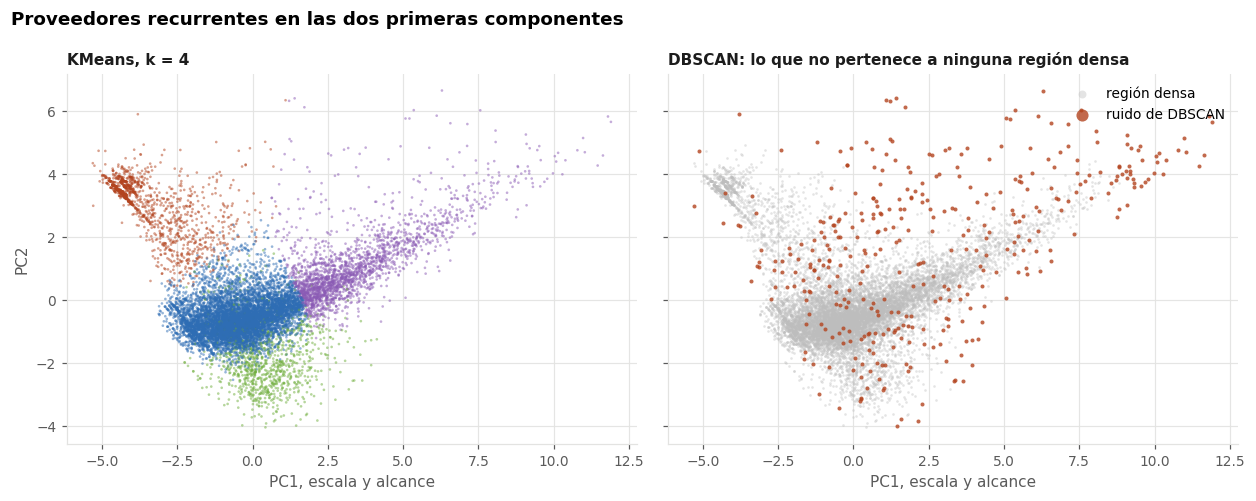

In [15]:
coord = X[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True, sharey=True)
colores = np.array(PALETA + ["#C9A227", "#6B6B6B", "#D17AA6", "#4F9D69", "#9C755F", "#A0CBE8", "#1D4A7C"])
axes[0].scatter(coord[:, 0], coord[:, 1], s=3, c=colores[etq % len(colores)], alpha=.5, lw=0, rasterized=True)
axes[0].set_title(f"KMeans, k = {K}", loc="left", fontsize=10)
ruido = etq_db == -1
axes[1].scatter(coord[~ruido, 0], coord[~ruido, 1], s=3, c="#BDBDBD", alpha=.4, lw=0, label="región densa", rasterized=True)
axes[1].scatter(coord[ruido, 0], coord[ruido, 1], s=7, c=ROJO, alpha=.8, lw=0, label="ruido de DBSCAN")
axes[1].set_title("DBSCAN: lo que no pertenece a ninguna región densa", loc="left", fontsize=10)
axes[1].legend(loc="upper right", markerscale=3)
for ax in axes:
    ax.set_xlabel("PC1, escala y alcance"); ax.grid(alpha=.9); ax.set_axisbelow(True)
axes[0].set_ylabel("PC2")
fig.suptitle("Proveedores recurrentes en las dos primeras componentes", x=.01, ha="left", fontweight="bold")
fig.tight_layout()
escala_ruido = local.n_ganados[ruido].median() / local.n_ganados[~ruido].median()
figura(fig, "f14_kmeans_dbscan", f"""
KMeans corta el continuo en {K} regiones contiguas, mientras DBSCAN deja en gris el núcleo denso y
marca en rojo {ruido.sum():,} proveedores, el {100*ruido.mean():.1f} por ciento, que no tienen
{MIN_PTS} vecinos a menos de {EPS:.2f}. El ruido no está repartido al azar. Se ubica en la periferia,
sobre todo a la derecha, donde hay pocos proveedores con un comportamiento parecido, y su mediana de
adjudicaciones es {escala_ruido:.1f} veces la del núcleo. Las dos componentes resumen solo una
parte de la varianza, por eso algunos puntos rojos parecen rodeados de grises: son raros en las
dimensiones que esta proyección no muestra.""")

**Qué agrega HDBSCAN.** HDBSCAN no reemplaza a KMeans como tipología, porque deja como ruido una parte grande de los proveedores, pero sí sirve para leerla mejor. Se cruzan sus grupos con los perfiles de KMeans y se miran tres cosas: qué perfil de KMeans casi no forma región densa y por eso queda como ruido, qué perfiles HDBSCAN parte en subgrupos y qué los distingue, y si aparece algún grupo que no responde al comportamiento del proveedor sino a cómo se registró el dato. Los rasgos de cada grupo se nombran con la misma regla que los clusters de KMeans. El ruido de HDBSCAN no es la cola de anomalías de la sección siguiente: son proveedores que quedan entre regiones densas, no necesariamente raros.

In [16]:
etq_h = local.hdbscan.values
cruce = pd.crosstab(etq_h, local.cluster.map(perfil.perfil))
z_h = pd.DataFrame(Z, columns=VARIABLES).groupby(etq_h).mean()
grupos_h = pd.DataFrame({
    "proveedores": cruce.sum(1),
    "perfil_kmeans": cruce.idxmax(1),
    "pct_de_ese_perfil": (100 * cruce.max(1) / cruce.sum(1)).round(0),
    "rasgos": z_h.apply(nombrar, axis=1),
    "familias_mediana": local.groupby(etq_h).n_familias.median(),
    "pct_personas_naturales": (100 * local.tipo.eq("persona natural").groupby(etq_h).mean()).round(0),
    "pct_extranjeros": (100 * local.tipo.eq("extranjero").groupby(etq_h).mean()).round(0)})
grupos_h.loc[-1, "rasgos"] = "ruido, entre regiones densas"
exportar(grupos_h.rename_axis("hdbscan").reset_index(), "p2_hdbscan", "Grupos de HDBSCAN frente a los perfiles de KMeans")

ruido_p = (cruce.loc[-1] / cruce.sum(0)).sort_values()
lectura = [f"HDBSCAN deja como ruido al {100*ruido_p.iloc[-1]:.0f} por ciento del perfil {ruido_p.index[-1]} y solo al "
           f"{100*ruido_p.iloc[0]:.0f} por ciento del perfil {ruido_p.index[0]}: el primero es el perfil menos homogéneo, "
           "KMeans lo agrupa por su rasgo dominante pero sus miembros no forman una región densa."]
for nombre_p in perfil.perfil:
    partes = grupos_h[(grupos_h.index != -1) & (grupos_h.perfil_kmeans == nombre_p) & (grupos_h.pct_de_ese_perfil >= 80)]
    if len(partes) < 2:
        continue
    a, b = partes.proveedores.nlargest(2).index
    var = (z_h.loc[a] - z_h.loc[b]).abs().idxmax()
    frase = (f"Parte el perfil {nombre_p} en dos grupos, de {grupos_h.proveedores[a]:,} y {grupos_h.proveedores[b]:,} "
             f"proveedores, que se distinguen sobre todo por {var}, con mediana {local[var][etq_h == a].median():g} "
             f"frente a {local[var][etq_h == b].median():g}")
    if abs(grupos_h.pct_extranjeros[a] - grupos_h.pct_extranjeros[b]) >= 10:
        frase += (f", y por la proporción de extranjeros, {grupos_h.pct_extranjeros[a]:.0f} frente a "
                  f"{grupos_h.pct_extranjeros[b]:.0f} por ciento")
    lectura.append(frase + ".")
sin_familia = grupos_h[(grupos_h.index != -1) & (grupos_h.familias_mediana == 0)]
if len(sin_familia):
    lectura.append(f"Además aísla {int(sin_familia.proveedores.sum()):,} proveedores cuya mediana de familias es cero: "
                   "sus adjudicaciones no traen código CUBSO, un grupo que existe por cómo se registró el dato y no "
                   "por cómo se comporta el proveedor, y que conviene no leer como un tipo de mercado.")
print("\n".join(lectura))
print("\nProveedores de cada perfil de KMeans según su grupo de HDBSCAN (-1 es ruido):")
print(cruce.T.to_string())
grupos_h.rename(index={-1: "ruido"})

HDBSCAN deja como ruido al 93 por ciento del perfil contratista de obra y solo al 21 por ciento del perfil competitivo típico: el primero es el perfil menos homogéneo, KMeans lo agrupa por su rasgo dominante pero sus miembros no forman una región densa.
Parte el perfil competitivo típico en dos grupos, de 3,561 y 2,904 proveedores, que se distinguen sobre todo por n_familias, con mediana 2 frente a 1.
Parte el perfil cautivo sin competencia en dos grupos, de 602 y 168 proveedores, que se distinguen sobre todo por n_familias, con mediana 1 frente a 2, y por la proporción de extranjeros, 13 frente a 35 por ciento.
Además aísla 267 proveedores cuya mediana de familias es cero: sus adjudicaciones no traen código CUBSO, un grupo que existe por cómo se registró el dato y no por cómo se comporta el proveedor, y que conviene no leer como un tipo de mercado.

Proveedores de cada perfil de KMeans según su grupo de HDBSCAN (-1 es ruido):
row_0                        -1    0    1    2   3     4   

,proveedores,perfil_kmeans,pct_de_ese_perfil,rasgos,familias_mediana,pct_personas_naturales,pct_extranjeros
ruido,4494,competitivo típico,35.0,"ruido, entre regiones densas",2.0,8.0,3.0
0,267,competitivo típico,100.0,"especializado, pocos clientes",0.0,30.0,0.0
1,602,cautivo sin competencia,100.0,"gana sin rivales, contratado sin concurso",1.0,82.0,13.0
2,168,cautivo sin competencia,100.0,"gana sin rivales, contratado sin concurso",2.0,56.0,35.0
3,66,contratista de obra,100.0,"obras, contratos grandes",2.0,6.0,0.0
4,2904,competitivo típico,96.0,"especializado, contratado por concurso",1.0,23.0,0.0
5,3561,competitivo típico,84.0,"muy diversificado, contratado por concurso",2.0,18.0,0.0


In [17]:
nombre_c = perfil.perfil[cautivo]
sub_c = grupos_h[(grupos_h.index != -1) & (grupos_h.perfil_kmeans == nombre_c) & (grupos_h.pct_de_ese_perfil >= 80)]
if len(sub_c) >= 2:
    esp, amp = sub_c.nlargest(2, "proveedores").sort_values("familias_mediana").index
    g = grupos_h.loc[[esp, amp]]
    hallazgo("II", "Los proveedores cautivos son dos grupos con preguntas de revisión distintas",
             f"""HDBSCAN parte el perfil cautivo en dos grupos que compiten igual de poco: ganan sin otro
             postor y sin concurso. {g.proveedores[esp]:,} proveedores atienden {g.familias_mediana[esp]:.0f}
             familia de producto en mediana y el {g.pct_personas_naturales[esp]:.0f} por ciento son personas
             naturales; los otros {g.proveedores[amp]:,} atienden {g.familias_mediana[amp]:.0f} familias y el
             {g.pct_extranjeros[amp]:.0f} por ciento son extranjeros, frente al {g.pct_extranjeros[esp]:.0f} por
             ciento del primer grupo. La falta de competencia es la misma, pero lo que se contrata y a quién
             no lo es.""",
             """Revisar cada grupo con su propia pregunta. En el primero, si la contratación directa repetida
             de la misma persona en un solo rubro debería pasar a una convocatoria abierta. En el segundo, si
             está documentado el sustento de exclusividad o proveedor único que permite contratar sin
             concurso a un proveedor extranjero.""",
             "p2_hdbscan, p2_perfiles")
else:
    print(f"HDBSCAN no parte el perfil {nombre_c} en subgrupos en esta corrida; no hay hallazgo que registrar.")


HALLAZGO. Los proveedores cautivos son dos grupos con preguntas de revisión distintas
HDBSCAN parte el perfil cautivo en dos grupos que compiten igual de poco: ganan sin otro postor y sin concurso. 602 proveedores atienden 1 familia de producto en mediana y el 82 por ciento son personas naturales; los otros 168 atienden 2 familias y el 35 por ciento son extranjeros, frente al 13 por ciento del primer grupo. La falta de competencia es la misma, pero lo que se contrata y a quién no lo es.
Accion propuesta: Revisar cada grupo con su propia pregunta. En el primero, si la contratación directa repetida de la misma persona en un solo rubro debería pasar a una convocatoria abierta. En el segundo, si está documentado el sustento de exclusividad o proveedor único que permite contratar sin concurso a un proveedor extranjero.



## 7. Anomalías: quiénes son y qué tienen de raro

Se combinan dos señales complementarias. Un proveedor es **anomalía** si DBSCAN lo marca como ruido y además está entre el 5 por ciento más lejano del centroide de su cluster de KMeans. Pedir las dos condiciones reduce los falsos positivos de cada método: el ruido de DBSCAN puede ser un punto en una zona poco poblada pero normal, y la distancia al centroide puede ser alta en un cluster muy extendido.

In [18]:
dist_c = np.sqrt(((X - C[etq]) ** 2).sum(1))
umbral = np.quantile(dist_c, .95)
local["dist_centroide"] = dist_c
local["anomalia"] = (etq_db == -1) & (dist_c >= umbral)
anom = local[local.anomalia].copy()
z_anom = pd.DataFrame(Z[local.anomalia.values], columns=VARIABLES)
anom["rasgo_extremo"] = [", ".join(f"{v} {'alto' if fila[v] > 0 else 'bajo'}"
                                   for v in fila.abs().sort_values(ascending=False).index[:2])
                         for _, fila in z_anom.iterrows()]
# Una anomalia es de competencia o dependencia si alguno de sus dos rasgos mas
# extremos lo es; si los dos son de tamano, alcance o rubro, es de escala.
COMPETENCIA = {"cuota_cliente_top", "tasa_victoria", "pct_postor_unico", "pct_sin_concurso"}
anom["tipo_anomalia"] = [("competencia o dependencia" if any(t.rsplit(" ", 1)[0] in COMPETENCIA
                                                             for t in r.split(", ")) else "escala")
                         for r in anom.rasgo_extremo]
anom_monto = anom.monto_total.sum() / local.monto_total.sum()
por_tipo = anom.groupby("tipo_anomalia").agg(proveedores=("nodo", "size"), monto=("monto_total", "sum"),
                                             postor_unico=("pct_postor_unico", "mean"),
                                             sin_concurso=("pct_sin_concurso", "mean"),
                                             entidades=("n_entidades", "median"))
por_rasgo = anom.rasgo_extremo.str.split(", ").explode().value_counts().head(10)
cola = anom[anom.tipo_anomalia == "competencia o dependencia"].sort_values("monto_total", ascending=False)
tabla_anom = (cola[["nombre", "tipo", "cluster", "n_ganados", "monto_total", "n_entidades",
                    "cuota_cliente_top", "tasa_victoria", "pct_postor_unico", "pct_sin_concurso",
                    "rasgo_extremo"]].head(25))
exportar(tabla_anom.round(3), "p2_anomalias", "Anomalias de competencia o dependencia, por monto")
exportar(por_tipo.reset_index().round(3), "p2_anomalias_tipo", "Anomalias por tipo de rareza")
print(f"{len(anom):,} anomalías, el {100*len(anom)/len(local):.1f} % de los recurrentes, "
      f"con el {100*anom_monto:.1f} % del monto")
por_tipo.round(3)

260 anomalías, el 2.2 % de los recurrentes, con el 36.4 % del monto


,proveedores,monto,postor_unico,sin_concurso,entidades
tipo_anomalia,,,,,
competencia o dependencia,77,1.346049e+09,0.731,0.939,4.0
escala,183,1.860734e+10,0.284,0.321,14.0



Lectura de f15_rasgos_anomalia
La mayoría de las 260 anomalías son raras por escala: 183 proveedores cuyos dos rasgos más extremos son de tamaño, alcance, continuidad o rubro, como los grandes proveedores nacionales de maquinaria, seguros o insumos médicos que le venden a más de cien entidades. Esa rareza es esperable y concentra casi todo el monto anómalo. La cola útil para supervisión es la otra: 77 proveedores raros por competencia o dependencia, con postor único en el 73 por ciento de lo que ganan y contratación sin concurso en el 94 por ciento. Separar las dos es lo que evita que la lista de anomalías sea, sin más, la lista de las empresas más grandes.



,nombre,tipo,cluster,n_ganados,monto_total,n_entidades,cuota_cliente_top,tasa_victoria,pct_postor_unico,pct_sin_concurso,rasgo_extremo
1596,FABRICA DE ARMAS Y MUNICIONES DEL EJERCITO SAC - FAME SAC,empresa,3,9,1.162866e+08,4,0.899006,0.562500,0.777778,0.888889,"monto_total alto, pct_sin_concurso alto"
6,CONSORCIO BRISTOL-MYERS SQUIBB PERU S.A. - PERUFARMA S.A.,consorcio,3,20,9.816967e+07,4,0.780631,1.000000,0.200000,0.950000,"monto_total alto, pct_sin_concurso alto"
6204,CONSORCIO QUIMICA SUIZA S.A.C. - ROCHE FARMA PERU S.A.,consorcio,3,29,7.200654e+07,8,0.669097,0.966667,0.137931,0.965517,"monto_total alto, pct_sin_concurso alto"
2169,"THALES DIS MEXICO, S.A. DE C.V. SUCURSAL DEL PERU",empresa,2,3,7.104604e+07,2,0.832204,1.000000,1.000000,1.000000,"monto_mediano alto, pct_postor_unico alto"
9407,HAUSSMANN ASSOCIÉS SELÀRL,extranjero,1,4,6.183799e+07,1,1.000000,1.000000,1.000000,1.000000,"monto_mediano alto, pct_postor_unico alto"
315,FOLEY HOAG LLP,extranjero,1,6,6.032332e+07,3,0.839862,1.000000,1.000000,1.000000,"monto_mediano alto, pct_postor_unico alto"
3963,SANOFI-AVENTIS DEL PERU S.A,empresa,3,13,5.376589e+07,6,0.891374,0.866667,0.615385,1.000000,"pct_sin_concurso alto, monto_total alto"
8014,JIFIFASA S.A.C.,empresa,2,6,4.872600e+07,2,0.954646,0.500000,0.166667,1.000000,"monto_mediano alto, pct_sin_concurso alto"
9281,CONSORCIO QUIMICA SUIZA S.A.C. - NOVO NORDISK PERU S.A.C.,consorcio,2,7,4.768129e+07,3,0.987841,1.000000,0.000000,1.000000,"pct_sin_concurso alto, monto_total alto"
11135,CENTRO DE DIALISIS KUSAQ SOCIEDAD ANONIMA CERRADA - CENKUS S...,empresa,2,4,4.641146e+07,2,0.959310,1.000000,1.000000,0.250000,"pct_postor_unico alto, monto_mediano alto"


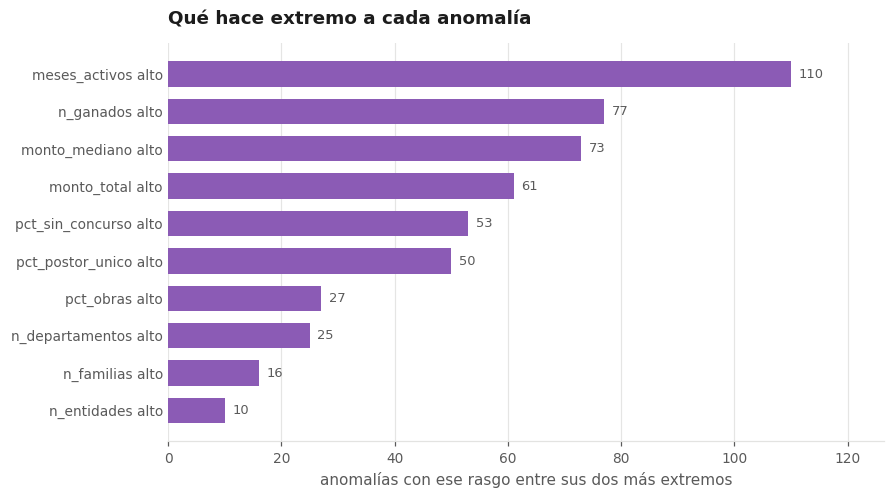

In [19]:
fig, ax = barras_h(por_rasgo.rename_axis("rasgo").reset_index(name="proveedores"), "rasgo", "proveedores",
                   "Qué hace extremo a cada anomalía", "anomalías con ese rasgo entre sus dos más extremos",
                   color=MORADO)
esc, com = por_tipo.loc["escala"], por_tipo.loc["competencia o dependencia"]
figura(fig, "f15_rasgos_anomalia", f"""
La mayoría de las {len(anom):,} anomalías son raras por escala: {int(esc.proveedores):,} proveedores
cuyos dos rasgos más extremos son de tamaño, alcance, continuidad o rubro, como los grandes proveedores
nacionales de maquinaria, seguros o insumos médicos que le venden a más de cien entidades. Esa
rareza es esperable y concentra casi todo el monto anómalo. La cola útil para supervisión es la
otra: {int(com.proveedores):,} proveedores raros por competencia o dependencia, con postor único en
el {100*com.postor_unico:.0f} por ciento de lo que ganan y contratación sin concurso en el
{100*com.sin_concurso:.0f} por ciento. Separar las dos es lo que evita que la lista de anomalías sea,
sin más, la lista de las empresas más grandes.""")
tabla_anom.head(12)

In [20]:
hallazgo("II", "Las anomalías útiles no son las más grandes sino las que ganan sin competir",
         f"""Combinar el ruido de DBSCAN con la distancia al centroide deja {len(anom):,} proveedores
         anómalos. {int(esc.proveedores):,} lo son por escala, y son los grandes proveedores nacionales.
         Los otros {int(com.proveedores):,} lo son por competencia o dependencia: ganan sin otro postor el
         {100*com.postor_unico:.0f} por ciento de las veces y suman S/ {com.monto/1e6:,.0f} millones.""",
         """Entregar al área de control solo la cola de competencia o dependencia, ordenada por monto, con
         el rasgo extremo como primera pregunta de revisión, y recalcularla cada trimestre con los mismos
         parámetros para ver quién entra y quién sale.""",
         "f15_rasgos_anomalia, p2_anomalias")


HALLAZGO. Las anomalías útiles no son las más grandes sino las que ganan sin competir
Combinar el ruido de DBSCAN con la distancia al centroide deja 260 proveedores anómalos. 183 lo son por escala, y son los grandes proveedores nacionales. Los otros 77 lo son por competencia o dependencia: ganan sin otro postor el 73 por ciento de las veces y suman S/ 1,346 millones.
Accion propuesta: Entregar al área de control solo la cola de competencia o dependencia, ordenada por monto, con el rasgo extremo como primera pregunta de revisión, y recalcularla cada trimestre con los mismos parámetros para ver quién entra y quién sale.



**Sensibilidad de la cola de anomalías.** La cola depende de dos cortes, el eps de DBSCAN y el cuantil de distancia al centroide, y ninguno es sagrado. Se mueven los dos, eps un 10 por ciento hacia cada lado y el cuantil entre 0,90 y 0,975, y se cuenta cuántas anomalías de competencia o dependencia salen y cuántas de las adoptadas siguen en la lista. Las dos señales no son independientes, porque las dos miden rareza en el mismo espacio de componentes, pero se complementan: una mira la densidad local y la otra la distancia al perfil del grupo.

In [21]:
adoptadas = set(anom.loc[anom.tipo_anomalia == "competencia o dependencia", "nodo"])

def de_competencia(mascara):
    """Nodos de la mascara cuyos dos rasgos mas extremos incluyen uno de competencia."""
    zf = pd.DataFrame(Z[mascara], columns=VARIABLES)
    dos = zf.abs().apply(lambda f: set(f.sort_values(ascending=False).index[:2]), axis=1)
    return set(local.nodo.values[mascara][[bool(d & COMPETENCIA) for d in dos]])

filas, listas = [], []
for factor in [.9, 1.0, 1.1]:
    ruido_f = dbscan(X, EPS * factor, MIN_PTS)[0] == -1
    for q in [.90, .95, .975]:
        mascara = ruido_f & (dist_c >= np.quantile(dist_c, q))
        com = de_competencia(mascara)
        listas.append(com)
        filas.append({"eps": round(EPS * factor, 3), "factor_eps": factor, "cuantil": q,
                      "anomalias": int(mascara.sum()), "competencia": len(com),
                      "adoptadas_que_siguen": len(com & adoptadas)})
sensibilidad = pd.DataFrame(filas)
exportar(sensibilidad, "p2_sensibilidad_anomalias", "Anomalias de competencia segun eps y cuantil de distancia")
nucleo = set.intersection(*listas)
anidadas = all(c <= adoptadas or adoptadas <= c for c in listas)
ruido_db = etq_db == -1
solape = (ruido_db & (dist_c >= umbral)).sum() / ruido_db.sum()
print(f"El {100*solape:.0f} por ciento del ruido de DBSCAN también está en el 5 por ciento más lejano de su "
      f"centroide. Según los cortes, la cola de competencia va de {sensibilidad.competencia.min()} a "
      f"{sensibilidad.competencia.max()} proveedores"
      + (", pero las listas están anidadas: con cortes más laxos contienen a las adoptadas y con cortes más "
         "estrictos son un subconjunto de ellas" if anidadas else "")
      + f". {len(nucleo)} proveedores aparecen en las nueve combinaciones: ese es el núcleo robusto de la "
      "cola, y el largo de la lista se puede ajustar a la capacidad de revisión.")
sensibilidad

El 70 por ciento del ruido de DBSCAN también está en el 5 por ciento más lejano de su centroide. Según los cortes, la cola de competencia va de 33 a 157 proveedores. 33 proveedores aparecen en las nueve combinaciones: ese es el núcleo robusto de la cola, y el largo de la lista se puede ajustar a la capacidad de revisión.


,eps,factor_eps,cuantil,anomalias,competencia,adoptadas_que_siguen
0,1.179,0.9,0.900,471,157,77
1,1.179,0.9,0.950,358,115,77
2,1.179,0.9,0.975,246,73,50
3,1.311,1.0,0.900,320,103,77
4,1.311,1.0,0.950,260,77,77
5,1.311,1.0,0.975,187,50,50
6,1.442,1.1,0.900,227,66,53
7,1.442,1.1,0.950,193,53,53
8,1.442,1.1,0.975,144,33,33


## 8. Exportación

Las etiquetas por proveedor van a data/processed para que las Partes IV a VI puedan comparar clusters, comunidades y embeddings. Para el reporte interactivo se exportan los centroides de cada k entre 2 y 10 y una muestra de puntos en sus coordenadas de PCA: con eso la página puede reasignar los puntos al cambiar k sin recalcular nada pesado.

In [22]:
etiquetas = local[["nodo", "clave", "cluster", "dbscan", "hdbscan", "hdb_prob", "dist_centroide", "anomalia"]]
spark.createDataFrame(etiquetas).write.mode("overwrite").parquet(str(BASE / "clusters_proveedores"))

idx = np.random.default_rng(1).choice(len(X), min(3000, len(X)), replace=False)
puntos = pd.DataFrame(X[idx, :K_PCA], columns=[f"pc{i+1}" for i in range(K_PCA)]).round(4)
puntos["nombre"] = local.nombre.values[idx]; puntos["anomalia"] = local.anomalia.values[idx]
exportar(puntos, "p2_puntos", "Muestra de proveedores en coordenadas de PCA para el reporte")
centros = []
for k in range(2, 11):
    _, Ck, _, _ = kmeans(X, k, semilla=7)
    for c, v in enumerate(Ck):
        centros.append({"k": k, "cluster": c, **{f"pc{i+1}": round(float(v[i]), 4) for i in range(K_PCA)}})
exportar(pd.DataFrame(centros), "p2_centroides", "Centroides de KMeans para k de 2 a 10")
exportar(pd.DataFrame(FIGURAS), "p2_figuras", "Figuras de la Parte II con su lectura")
exportar(pd.DataFrame(HALLAZGOS), "p2_hallazgos", "Hallazgos de la Parte II con su accion propuesta")
pd.DataFrame(HALLAZGOS)[["titulo", "accion"]]

,titulo,accion
0,Existe un perfil de proveedor cautivo y se puede aislar,Usar el cluster 1 como lista de vigilancia: para cada par en...
1,Los proveedores cautivos son dos grupos con preguntas de rev...,"Revisar cada grupo con su propia pregunta. En el primero, si..."
2,Las anomalías útiles no son las más grandes sino las que gan...,Entregar al área de control solo la cola de competencia o de...


**Cierre.** La pregunta 1 queda respondida con dos resultados que se refuerzan. KMeans++, con k elegido por codo y silueta y confirmado por el jerárquico de Ward, separa perfiles de comportamiento, y uno de ellos es el del proveedor cautivo de una entidad que gana sin competencia. DBSCAN y la distancia al centroide, juntos, dejan una cola de revisión corta en la que cada proveedor llega con la razón por la que es raro.

Todo es una señal descriptiva para priorizar revisión. Un proveedor cautivo puede ser el único que atiende un rubro en una provincia alejada, y una anomalía puede ser una empresa grande y perfectamente regular; la tipología dice dónde mirar primero, no qué se encontrará.

In [23]:
spark.stop()